# 🩺 Diabetes Diagnosis Full Pipeline
## Hệ thống Chẩn đoán Tiểu đường với Machine Learning & RAG

**Dữ liệu**: BRFSS 2015 (Behavioral Risk Factor Surveillance System)  
**Mục tiêu**: Phân loại nhị phân — có/không có bệnh tiểu đường  
**Pipeline**: EDA → Train 9 Models → Cross-test → RAG PDF → Save

---

## 📦 SECTION 1 — Setup & Load Data

In [1]:
# === IMPORTS ===
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import joblib
import warnings
import json
import sys
import os
from pathlib import Path

# Sklearn
from sklearn.model_selection import (
    train_test_split, cross_val_score, StratifiedKFold,
    GridSearchCV, RandomizedSearchCV, learning_curve
)
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve, precision_recall_curve,
    classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier,
    AdaBoostClassifier, BaggingClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.feature_selection import mutual_info_classif

# XGBoost & LightGBM
try:
    import xgboost as xgb
    print(f'XGBoost version: {xgb.__version__}')
except ImportError:
    print('XGBoost not installed. Run: pip install xgboost')

try:
    import lightgbm as lgb
    print(f'LightGBM version: {lgb.__version__}')
except ImportError:
    print('LightGBM not installed. Run: pip install lightgbm')

warnings.filterwarnings('ignore')
matplotlib.rcParams['figure.dpi'] = 100
sns.set_style('whitegrid')
print('✅ All imports successful!')

XGBoost version: 3.4.1
LightGBM version: 4.7.0
✅ All imports successful!


In [2]:
# === CONFIG ===
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Paths
BASE_DIR = Path('..').resolve()
DATA_DIR = BASE_DIR / 'data'
REPORTS_DIR = BASE_DIR / 'reports' / 'figures'
MODELS_DIR = BASE_DIR / 'models'

TRAIN_CSV = DATA_DIR / 'diabetes_binary_5050split_health_indicators_BRFSS2015.csv'
TEST_CSV  = DATA_DIR / 'diabetes_binary_health_indicators_BRFSS2015.csv'
PDF_PATH  = BASE_DIR / 'HD-chan-doan-dieu-tri-DTD-2017_07_19-Approved.pdf'
if not PDF_PATH.exists():
    PDF_PATH = DATA_DIR / 'HD-chan-doan-dieu-tri-DTD-2017_07_19-Approved.pdf'

# Create directories
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print(f'BASE_DIR   : {BASE_DIR}')
print(f'TRAIN CSV  : {TRAIN_CSV} | exists={TRAIN_CSV.exists()}')
print(f'TEST CSV   : {TEST_CSV}  | exists={TEST_CSV.exists()}')
print(f'PDF PATH   : {PDF_PATH}  | exists={PDF_PATH.exists()}')

BASE_DIR   : D:\N4_K1\HTTM\Code\TieuLuan\KB_RAG
TRAIN CSV  : D:\N4_K1\HTTM\Code\TieuLuan\KB_RAG\data\diabetes_binary_5050split_health_indicators_BRFSS2015.csv | exists=True
TEST CSV   : D:\N4_K1\HTTM\Code\TieuLuan\KB_RAG\data\diabetes_binary_health_indicators_BRFSS2015.csv  | exists=True
PDF PATH   : D:\N4_K1\HTTM\Code\TieuLuan\KB_RAG\data\HD-chan-doan-dieu-tri-DTD-2017_07_19-Approved.pdf  | exists=True


In [3]:
# === LOAD DATASETS ===
try:
    df_train = pd.read_csv(TRAIN_CSV)
    print(f'✅ Train dataset loaded: {df_train.shape}')
except FileNotFoundError:
    raise FileNotFoundError(f'❌ Train file not found: {TRAIN_CSV}\nPlease place the CSV in the data/ folder.')

try:
    df_test = pd.read_csv(TEST_CSV)
    print(f'✅ Test dataset loaded:  {df_test.shape}')
except FileNotFoundError:
    raise FileNotFoundError(f'❌ Test file not found: {TEST_CSV}\nPlease place the CSV in the data/ folder.')

TARGET_COL = 'Diabetes_binary'
print(f'Target column: {TARGET_COL}')

✅ Train dataset loaded: (70692, 22)
✅ Test dataset loaded:  (253680, 22)
Target column: Diabetes_binary


In [4]:
# === QUICK INSPECTION ===
print('=== TRAIN DATASET ===')
print(f'Shape: {df_train.shape}')
print(f'\nDtypes:\n{df_train.dtypes.value_counts()}')
print(f'\nTarget distribution:\n{df_train[TARGET_COL].value_counts()}')
display(df_train.head())

print('\n=== TEST DATASET ===')
print(f'Shape: {df_test.shape}')
print(f'\nTarget distribution:\n{df_test[TARGET_COL].value_counts()}')
display(df_test.head())

=== TRAIN DATASET ===
Shape: (70692, 22)

Dtypes:
float64    22
Name: count, dtype: int64

Target distribution:
Diabetes_binary
0.0    35346
1.0    35346
Name: count, dtype: int64


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0



=== TEST DATASET ===
Shape: (253680, 22)

Target distribution:
Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


---
## 📊 SECTION 2 — EDA & Preprocessing

In [5]:
# === DATA QUALITY CHECK ===
def data_quality_report(df, name='Dataset'):
    print(f'\n=== {name} Quality Report ===')
    print(f'Shape          : {df.shape}')
    print(f'Missing values : {df.isnull().sum().sum()}')
    print(f'Duplicates     : {df.duplicated().sum()}')
    print(f'\nDtype summary:')
    print(df.dtypes.value_counts())
    print(f'\nBasic stats:')
    display(df.describe().round(3))

data_quality_report(df_train, 'Train (5050 split)')
data_quality_report(df_test,  'Test  (binary)')


=== Train (5050 split) Quality Report ===
Shape          : (70692, 22)
Missing values : 0
Duplicates     : 1635

Dtype summary:
float64    22
Name: count, dtype: int64

Basic stats:


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
count,70692.0,70692.000,70692.000,70692.000,70692.000,70692.000,70692.000,70692.000,70692.000,70692.000,...,70692.000,70692.000,70692.000,70692.000,70692.000,70692.000,70692.000,70692.000,70692.000,70692.000
mean,0.5,0.563,0.526,0.975,29.857,0.475,0.062,0.148,0.703,0.612,...,0.955,0.094,2.837,3.752,5.810,0.253,0.457,8.584,4.921,5.698
std,0.5,0.496,0.499,0.155,7.114,0.499,0.241,0.355,0.457,0.487,...,0.207,0.292,1.114,8.156,10.062,0.435,0.498,2.852,1.029,2.175
min,0.0,0.000,0.000,0.000,12.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,1.000,1.000
25%,0.0,0.000,0.000,1.000,25.000,0.000,0.000,0.000,0.000,0.000,...,1.000,0.000,2.000,0.000,0.000,0.000,0.000,7.000,4.000,4.000
50%,0.5,1.000,1.000,1.000,29.000,0.000,0.000,0.000,1.000,1.000,...,1.000,0.000,3.000,0.000,0.000,0.000,0.000,9.000,5.000,6.000
75%,1.0,1.000,1.000,1.000,33.000,1.000,0.000,0.000,1.000,1.000,...,1.000,0.000,4.000,2.000,6.000,1.000,1.000,11.000,6.000,8.000
max,1.0,1.000,1.000,1.000,98.000,1.000,1.000,1.000,1.000,1.000,...,1.000,1.000,5.000,30.000,30.000,1.000,1.000,13.000,6.000,8.000



=== Test  (binary) Quality Report ===
Shape          : (253680, 22)
Missing values : 0
Duplicates     : 24206

Dtype summary:
float64    22
Name: count, dtype: int64

Basic stats:


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
count,253680.000,253680.000,253680.000,253680.000,253680.000,253680.000,253680.000,253680.000,253680.000,253680.000,...,253680.000,253680.000,253680.000,253680.000,253680.000,253680.000,253680.000,253680.000,253680.000,253680.000
mean,0.139,0.429,0.424,0.963,28.382,0.443,0.041,0.094,0.757,0.634,...,0.951,0.084,2.511,3.185,4.242,0.168,0.440,8.032,5.050,6.054
std,0.346,0.495,0.494,0.190,6.609,0.497,0.197,0.292,0.429,0.482,...,0.216,0.278,1.068,7.413,8.718,0.374,0.496,3.054,0.986,2.071
min,0.000,0.000,0.000,0.000,12.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,1.000,1.000
25%,0.000,0.000,0.000,1.000,24.000,0.000,0.000,0.000,1.000,0.000,...,1.000,0.000,2.000,0.000,0.000,0.000,0.000,6.000,4.000,5.000
50%,0.000,0.000,0.000,1.000,27.000,0.000,0.000,0.000,1.000,1.000,...,1.000,0.000,2.000,0.000,0.000,0.000,0.000,8.000,5.000,7.000
75%,0.000,1.000,1.000,1.000,31.000,1.000,0.000,0.000,1.000,1.000,...,1.000,0.000,3.000,2.000,3.000,0.000,1.000,10.000,6.000,8.000
max,1.000,1.000,1.000,1.000,98.000,1.000,1.000,1.000,1.000,1.000,...,1.000,1.000,5.000,30.000,30.000,1.000,1.000,13.000,6.000,8.000


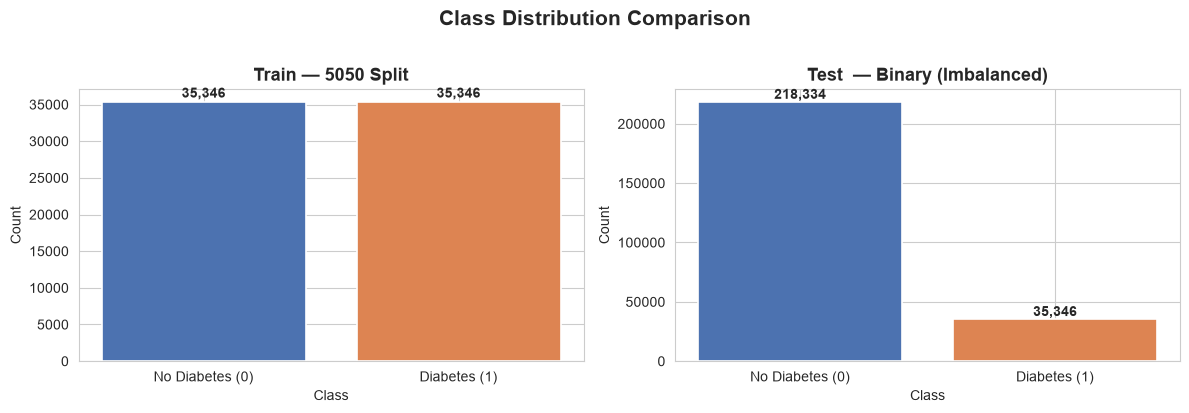

Train class ratio: {0.0: 0.5, 1.0: 0.5}
Test  class ratio: {0.0: 0.861, 1.0: 0.139}


In [6]:
# === CLASS DISTRIBUTION ===
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (df, title) in zip(axes, [
    (df_train, 'Train — 5050 Split'),
    (df_test,  'Test  — Binary (Imbalanced)')
]):
    counts = df[TARGET_COL].value_counts()
    bars = ax.bar(['No Diabetes (0)', 'Diabetes (1)'],
                  [counts.get(0, 0), counts.get(1, 0)],
                  color=['#4C72B0', '#DD8452'], edgecolor='white', linewidth=1.2)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
                f'{bar.get_height():,.0f}', ha='center', va='bottom', fontweight='bold')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_ylabel('Count')
    ax.set_xlabel('Class')

plt.suptitle('Class Distribution Comparison', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'class_distribution.png', bbox_inches='tight')
plt.show()
print(f'Train class ratio: {df_train[TARGET_COL].value_counts(normalize=True).round(3).to_dict()}')
print(f'Test  class ratio: {df_test[TARGET_COL].value_counts(normalize=True).round(3).to_dict()}')

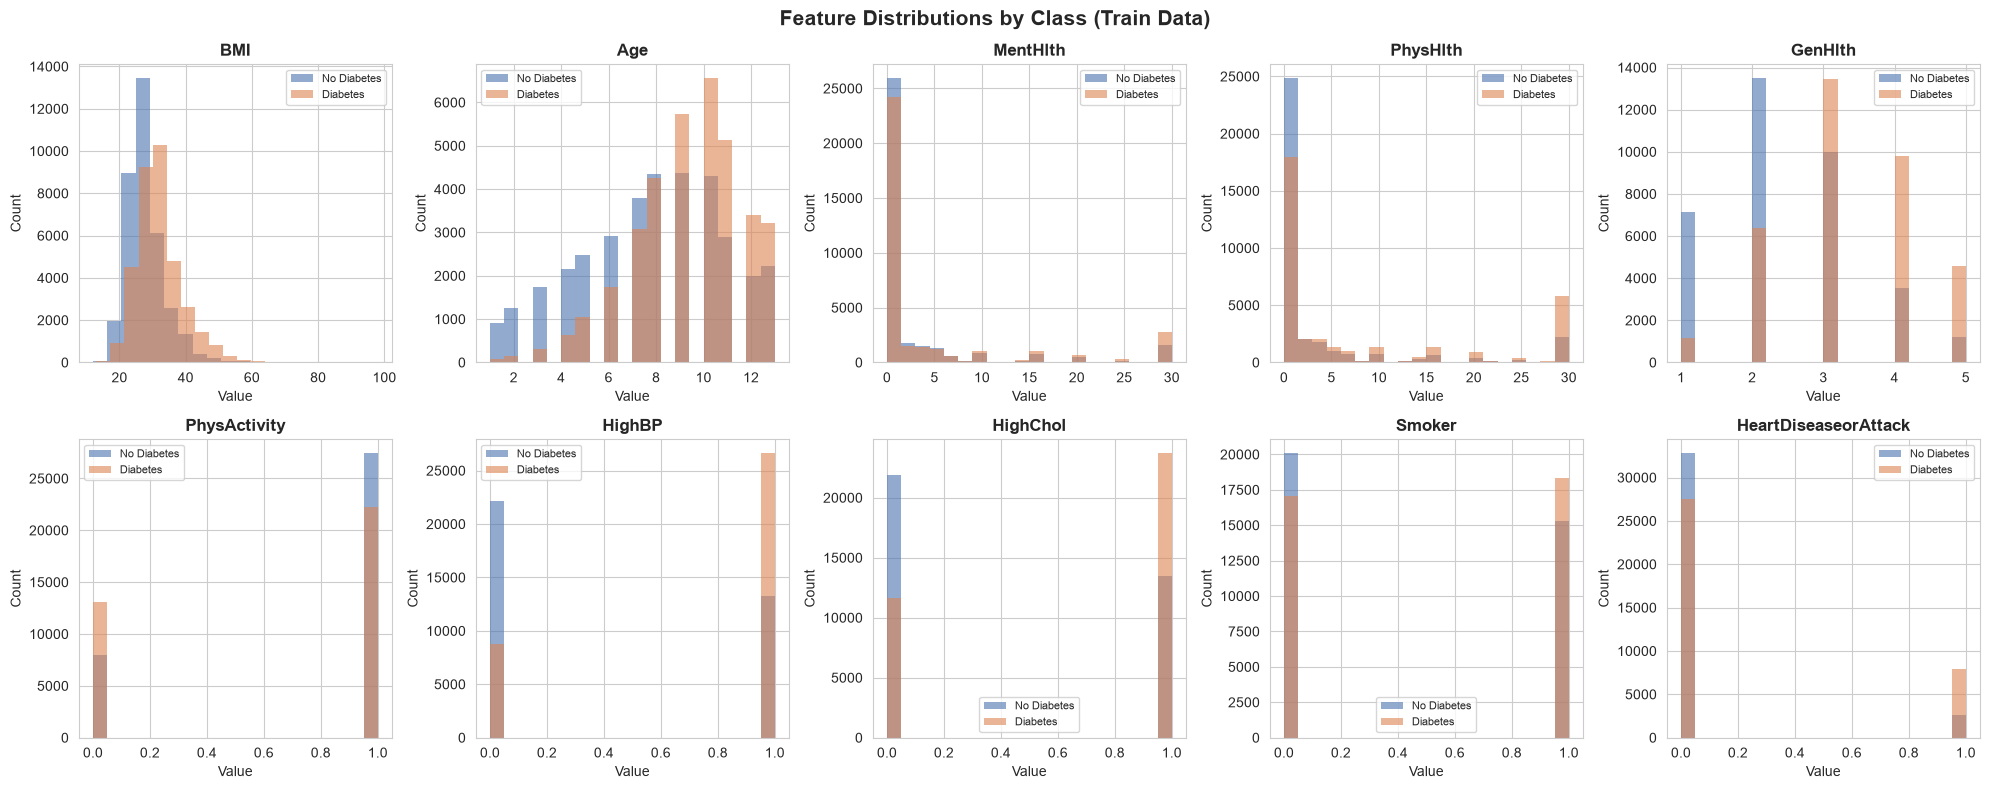

In [7]:
# === FEATURE DISTRIBUTIONS (TOP FEATURES) ===
TOP_FEATURES = ['BMI', 'Age', 'MentHlth', 'PhysHlth', 'GenHlth',
                'PhysActivity', 'HighBP', 'HighChol', 'Smoker', 'HeartDiseaseorAttack']
available_features = [f for f in TOP_FEATURES if f in df_train.columns]

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, feat in enumerate(available_features[:10]):
    for cls, color, label in [(0, '#4C72B0', 'No Diabetes'), (1, '#DD8452', 'Diabetes')]:
        subset = df_train[df_train[TARGET_COL] == cls][feat]
        axes[i].hist(subset, bins=20, alpha=0.6, color=color, label=label, edgecolor='none')
    axes[i].set_title(feat, fontweight='bold')
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Count')
    axes[i].legend(fontsize=8)

for j in range(len(available_features), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Feature Distributions by Class (Train Data)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'feature_distributions.png', bbox_inches='tight')
plt.show()

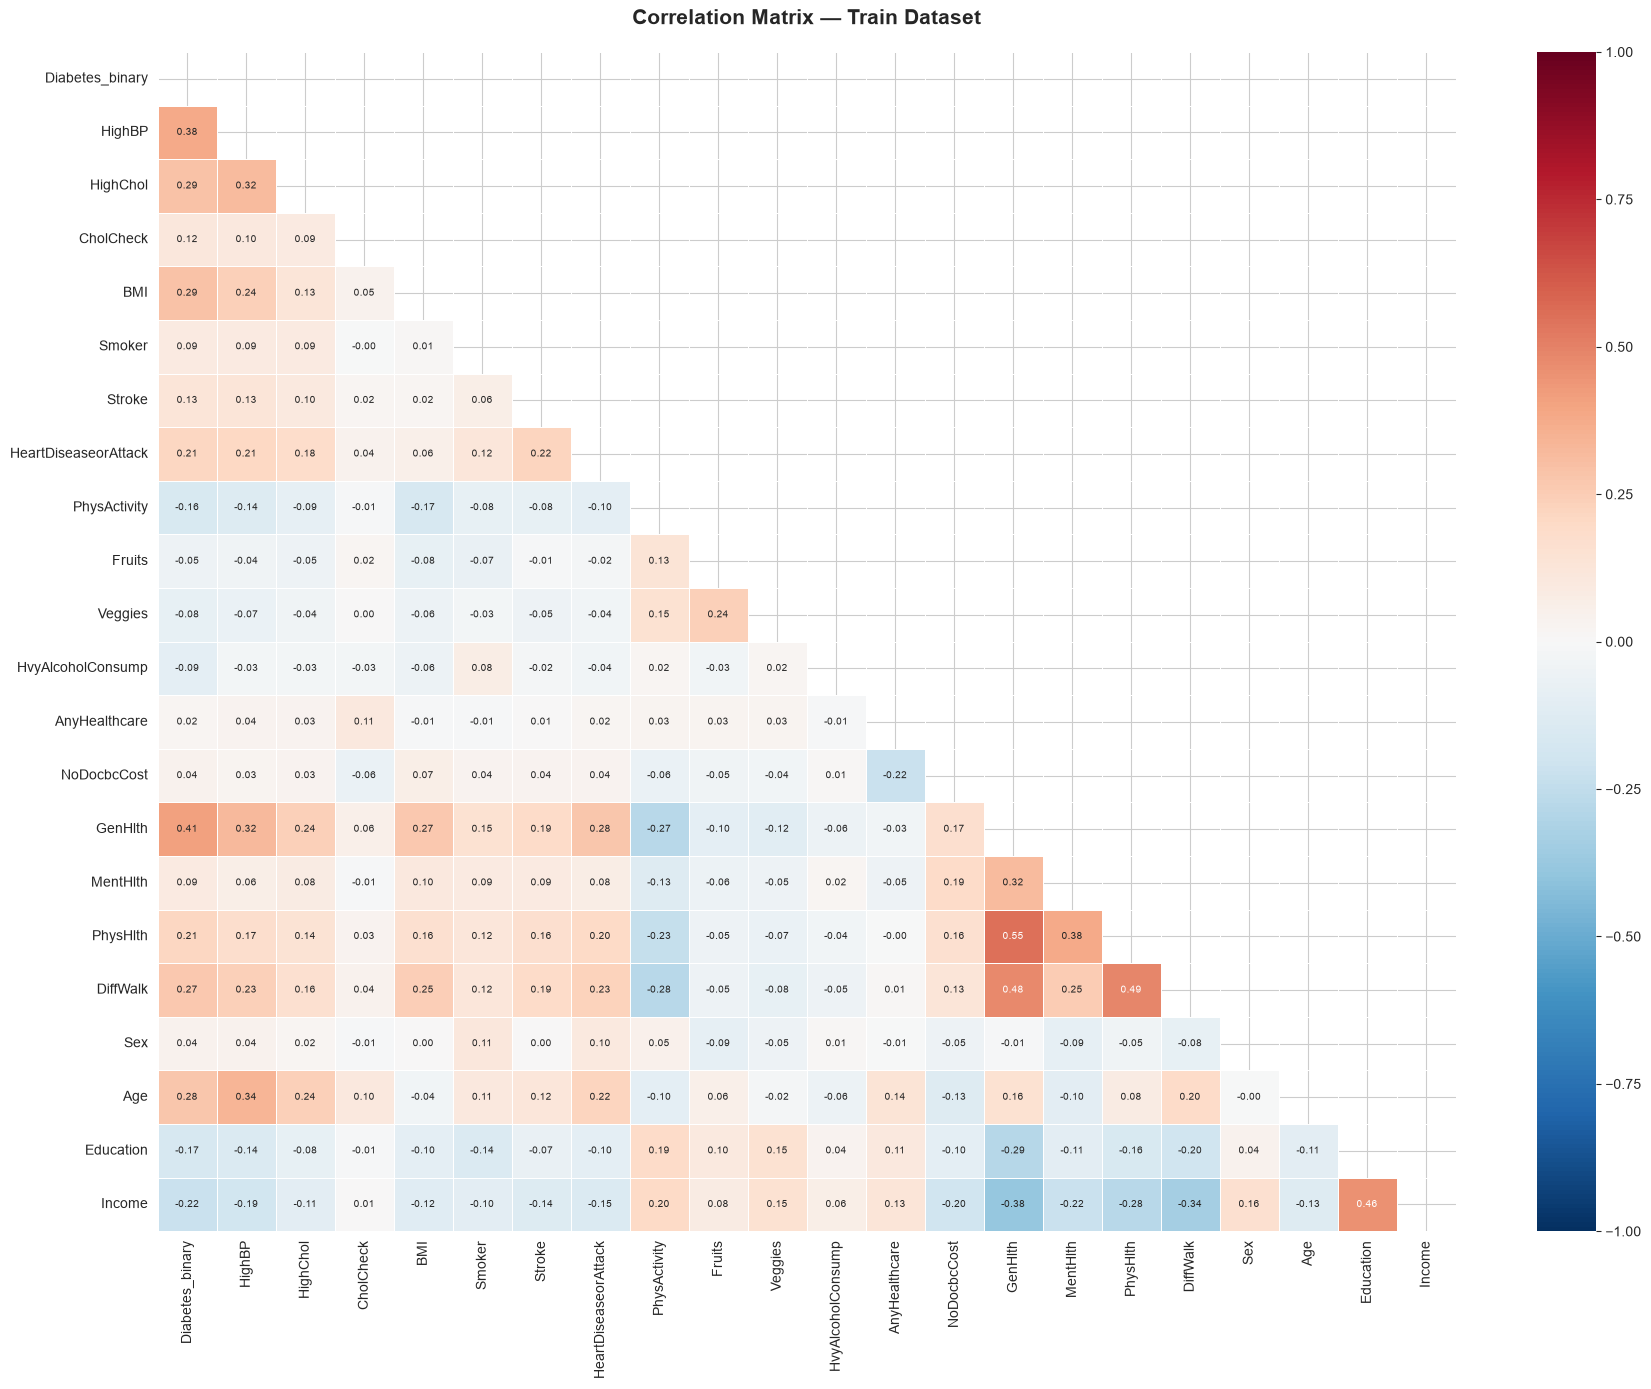


Top 10 features correlated with target:
GenHlth                 0.407612
HighBP                  0.381516
BMI                     0.293373
HighChol                0.289213
Age                     0.278738
DiffWalk                0.272646
Income                  0.224449
PhysHlth                0.213081
HeartDiseaseorAttack    0.211523
Education               0.170481
Name: Diabetes_binary, dtype: float64


In [8]:
# === CORRELATION HEATMAP ===
corr_matrix = df_train.corr()

fig, ax = plt.subplots(figsize=(18, 14))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt='.2f',
    cmap='RdBu_r', center=0, vmin=-1, vmax=1,
    linewidths=0.5, ax=ax, annot_kws={'size': 7}
)
ax.set_title('Correlation Matrix — Train Dataset', fontsize=15, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'correlation_heatmap.png', bbox_inches='tight')
plt.show()

# Top correlations with target
target_corr = corr_matrix[TARGET_COL].drop(TARGET_COL).abs().sort_values(ascending=False)
print('\nTop 10 features correlated with target:')
print(target_corr.head(10))

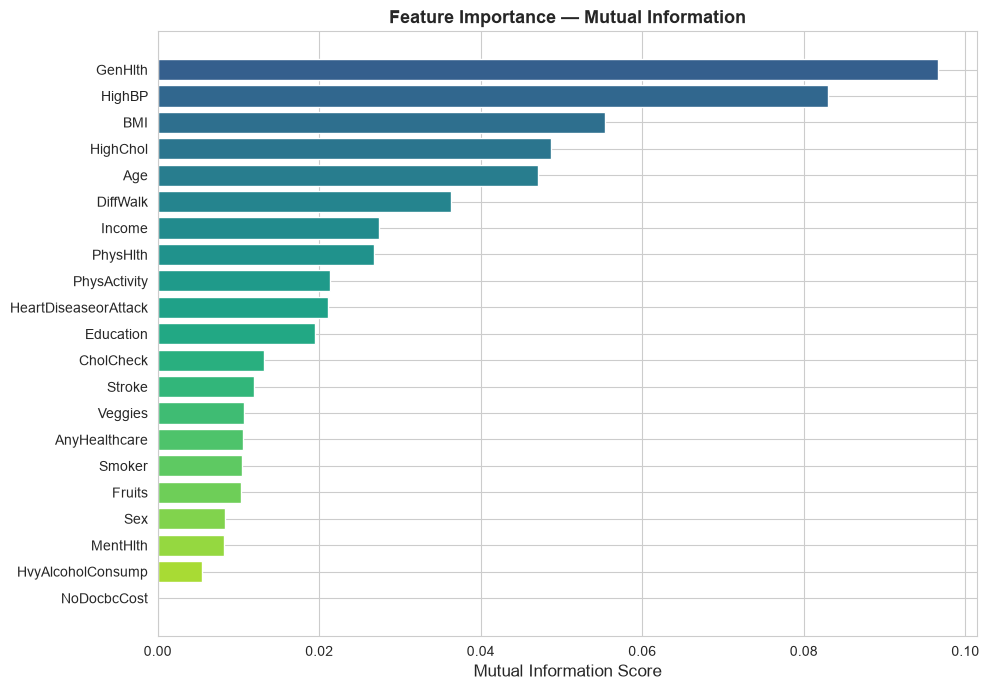

             Feature  MI_Score
             GenHlth  0.096661
              HighBP  0.082962
                 BMI  0.055356
            HighChol  0.048722
                 Age  0.047137
            DiffWalk  0.036359
              Income  0.027435
            PhysHlth  0.026750
        PhysActivity  0.021337
HeartDiseaseorAttack  0.021081
           Education  0.019432
           CholCheck  0.013210
              Stroke  0.011958
             Veggies  0.010623
       AnyHealthcare  0.010566
              Smoker  0.010409
              Fruits  0.010288
                 Sex  0.008361
            MentHlth  0.008154
   HvyAlcoholConsump  0.005528
         NoDocbcCost  0.000000


In [9]:
# === MUTUAL INFORMATION FEATURE IMPORTANCE ===
X_mi = df_train.drop(columns=[TARGET_COL])
y_mi = df_train[TARGET_COL]

mi_scores = mutual_info_classif(X_mi, y_mi, random_state=RANDOM_SEED)
mi_df = pd.DataFrame({'Feature': X_mi.columns, 'MI_Score': mi_scores})
mi_df = mi_df.sort_values('MI_Score', ascending=False)

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(mi_df['Feature'], mi_df['MI_Score'],
               color=plt.cm.viridis(np.linspace(0.3, 0.9, len(mi_df))))
ax.set_xlabel('Mutual Information Score', fontsize=12)
ax.set_title('Feature Importance — Mutual Information', fontsize=13, fontweight='bold')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'mutual_information.png', bbox_inches='tight')
plt.show()
print(mi_df.to_string(index=False))

In [10]:
# === PREPROCESSING ===
# 1. Drop duplicates
n_before = len(df_train)
df_train_clean = df_train.drop_duplicates().reset_index(drop=True)
print(f'Dropped {n_before - len(df_train_clean)} duplicate rows from train set.')
print(f'Train size: {n_before} → {len(df_train_clean)}')

# 2. Features & target
FEATURE_COLS = [c for c in df_train_clean.columns if c != TARGET_COL]
NUMERIC_FEATURES = ['BMI', 'MentHlth', 'PhysHlth', 'Age']
NUMERIC_FEATURES = [f for f in NUMERIC_FEATURES if f in FEATURE_COLS]

X = df_train_clean[FEATURE_COLS].values
y = df_train_clean[TARGET_COL].values

# 3. Train/Validation split 80/20 stratified
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)
print(f'\nTrain size: {X_train.shape}, Val size: {X_val.shape}')
print(f'Train class balance: {np.bincount(y_train.astype(int))}')
print(f'Val   class balance: {np.bincount(y_val.astype(int))}')

# 4. StandardScaler
scaler = StandardScaler()
numeric_idx = [FEATURE_COLS.index(f) for f in NUMERIC_FEATURES if f in FEATURE_COLS]

X_train_sc = X_train.copy()
X_val_sc   = X_val.copy()
X_train_sc[:, numeric_idx] = scaler.fit_transform(X_train[:, numeric_idx])
X_val_sc[:, numeric_idx]   = scaler.transform(X_val[:, numeric_idx])

print(f'\nScaled numeric features: {NUMERIC_FEATURES}')
print('✅ Preprocessing complete!')

Dropped 1635 duplicate rows from train set.
Train size: 70692 → 69057

Train size: (55245, 21), Val size: (13812, 21)
Train class balance: [27168 28077]
Val   class balance: [6792 7020]

Scaled numeric features: ['BMI', 'MentHlth', 'PhysHlth', 'Age']
✅ Preprocessing complete!


---
## 🤖 SECTION 3 — Train 9 Models & Compare

In [11]:
# === DEFINE 9 MODELS ===
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_SEED, C=1.0),
    'Decision Tree':       DecisionTreeClassifier(max_depth=10, random_state=RANDOM_SEED),
    'Random Forest':       RandomForestClassifier(n_estimators=100, max_depth=15, random_state=RANDOM_SEED, n_jobs=-1),
    'Gradient Boosting':   GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_SEED),
    'AdaBoost':            AdaBoostClassifier(n_estimators=100, random_state=RANDOM_SEED),
    'KNN':                 KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    'Naive Bayes':         GaussianNB(),
    'XGBoost':             xgb.XGBClassifier(n_estimators=100, use_label_encoder=False,
                                              eval_metric='logloss', random_state=RANDOM_SEED, n_jobs=-1),
    'LightGBM':            lgb.LGBMClassifier(n_estimators=100, random_state=RANDOM_SEED, n_jobs=-1, verbose=-1),
}
print(f'Defined {len(models)} models:')
for name in models:
    print(f'  • {name}')

Defined 9 models:
  • Logistic Regression
  • Decision Tree
  • Random Forest
  • Gradient Boosting
  • AdaBoost
  • KNN
  • Naive Bayes
  • XGBoost
  • LightGBM


In [12]:
%%time
# === TRAIN LOOP WITH 5-FOLD CROSS VALIDATION ===
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
results = []
trained_models = {}

for name, model in models.items():
    print(f'Training: {name}...', end=' ')
    
    # Cross-validation on train set
    cv_acc  = cross_val_score(model, X_train_sc, y_train, cv=cv, scoring='accuracy',  n_jobs=-1)
    cv_f1   = cross_val_score(model, X_train_sc, y_train, cv=cv, scoring='f1',        n_jobs=-1)
    cv_prec = cross_val_score(model, X_train_sc, y_train, cv=cv, scoring='precision', n_jobs=-1)
    cv_rec  = cross_val_score(model, X_train_sc, y_train, cv=cv, scoring='recall',    n_jobs=-1)
    cv_roc  = cross_val_score(model, X_train_sc, y_train, cv=cv, scoring='roc_auc',   n_jobs=-1)
    
    # Fit on full train, evaluate on val
    model.fit(X_train_sc, y_train)
    y_pred = model.predict(X_val_sc)
    y_prob = model.predict_proba(X_val_sc)[:, 1] if hasattr(model, 'predict_proba') else None
    
    val_acc  = accuracy_score(y_val, y_pred)
    val_f1   = f1_score(y_val, y_pred)
    val_prec = precision_score(y_val, y_pred)
    val_rec  = recall_score(y_val, y_pred)
    val_auc  = roc_auc_score(y_val, y_prob) if y_prob is not None else np.nan
    
    trained_models[name] = model
    results.append({
        'Model':         name,
        'CV_Accuracy':   cv_acc.mean(),
        'CV_F1':         cv_f1.mean(),
        'CV_Precision':  cv_prec.mean(),
        'CV_Recall':     cv_rec.mean(),
        'CV_AUC':        cv_roc.mean(),
        'Val_Accuracy':  val_acc,
        'Val_F1':        val_f1,
        'Val_Precision': val_prec,
        'Val_Recall':    val_rec,
        'Val_AUC':       val_auc,
    })
    print(f'Val Acc={val_acc:.4f} | F1={val_f1:.4f} | AUC={val_auc:.4f}')

results_df = pd.DataFrame(results).sort_values('Val_AUC', ascending=False).reset_index(drop=True)
print('\n✅ Training complete!')

Training: Logistic Regression... Val Acc=0.7446 | F1=0.7546 | AUC=0.8174
Training: Decision Tree... Val Acc=0.7316 | F1=0.7465 | AUC=0.7927
Training: Random Forest... Val Acc=0.7428 | F1=0.7584 | AUC=0.8181
Training: Gradient Boosting... Val Acc=0.7500 | F1=0.7646 | AUC=0.8237
Training: AdaBoost... Val Acc=0.7467 | F1=0.7592 | AUC=0.8194
Training: KNN... Val Acc=0.7047 | F1=0.7171 | AUC=0.7669
Training: Naive Bayes... Val Acc=0.7186 | F1=0.7217 | AUC=0.7800
Training: XGBoost... Val Acc=0.7420 | F1=0.7562 | AUC=0.8174
Training: LightGBM... Val Acc=0.7493 | F1=0.7641 | AUC=0.8234

✅ Training complete!
CPU times: total: 40.4 s
Wall time: 4min 10s


In [13]:
# === RESULTS TABLE ===
display_cols = ['Model', 'CV_Accuracy', 'CV_F1', 'CV_AUC', 'Val_Accuracy', 'Val_F1', 'Val_AUC']
display(results_df[display_cols].style
    .background_gradient(subset=['Val_AUC', 'Val_F1', 'Val_Accuracy'], cmap='YlOrRd')
    .format({c: '{:.4f}' for c in display_cols if c != 'Model'})
    .set_caption('Model Performance Summary')
)

best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]
print(f'\n🏆 Best model: {best_model_name} (Val AUC = {results_df.iloc[0]["Val_AUC"]:.4f})')

,Model,CV_Accuracy,CV_F1,CV_AUC,Val_Accuracy,Val_F1,Val_AUC
0,Gradient Boosting,0.7495,0.7634,0.8259,0.7500,0.7646,0.8237
1,LightGBM,0.7487,0.7635,0.8254,0.7493,0.7641,0.8234
2,AdaBoost,0.7445,0.7534,0.8213,0.7467,0.7592,0.8194
3,Random Forest,0.7463,0.7610,0.8208,0.7428,0.7584,0.8181
4,XGBoost,0.7443,0.7583,0.8176,0.7420,0.7562,0.8174
5,Logistic Regression,0.7447,0.7543,0.8200,0.7446,0.7546,0.8174
6,Decision Tree,0.7315,0.7459,0.7948,0.7316,0.7465,0.7927
7,Naive Bayes,0.7170,0.7200,0.7814,0.7186,0.7217,0.7800
8,KNN,0.7058,0.7190,0.7629,0.7047,0.7171,0.7669



🏆 Best model: Gradient Boosting (Val AUC = 0.8237)


In [14]:
%%time
# === HYPERPARAMETER TUNING — TOP 3 MODELS ===
param_grids = {
    'Random Forest': {
        'n_estimators': [100, 200],
        'max_depth': [10, 15, 20],
        'min_samples_split': [2, 5],
        'min_samples_leaf': [1, 2]
    },
    'XGBoost': {
        'n_estimators': [100, 200],
        'max_depth': [4, 6, 8],
        'learning_rate': [0.05, 0.1, 0.2],
        'subsample': [0.8, 1.0]
    },
    'LightGBM': {
        'n_estimators': [100, 200],
        'max_depth': [5, 7, 10],
        'learning_rate': [0.05, 0.1],
        'num_leaves': [31, 63]
    }
}

tuned_models = {}
tuning_results = []

base_models_map = {
    'Random Forest': RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=-1),
    'XGBoost':       xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss',
                                        random_state=RANDOM_SEED, n_jobs=-1),
    'LightGBM':      lgb.LGBMClassifier(random_state=RANDOM_SEED, n_jobs=-1, verbose=-1),
}

for name, param_grid in param_grids.items():
    print(f'\nTuning {name}...')
    search = RandomizedSearchCV(
        base_models_map[name], param_grid, n_iter=20,
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_SEED),
        scoring='roc_auc', n_jobs=-1, random_state=RANDOM_SEED, verbose=0
    )
    search.fit(X_train_sc, y_train)
    
    best = search.best_estimator_
    y_pred = best.predict(X_val_sc)
    y_prob = best.predict_proba(X_val_sc)[:, 1]
    
    tuned_models[name] = best
    tuning_results.append({
        'Model':        f'{name} (Tuned)',
        'Best_Params':  str(search.best_params_),
        'CV_AUC':       search.best_score_,
        'Val_Accuracy': accuracy_score(y_val, y_pred),
        'Val_F1':       f1_score(y_val, y_pred),
        'Val_AUC':      roc_auc_score(y_val, y_prob),
    })
    print(f'  Best params: {search.best_params_}')
    print(f'  Val AUC: {roc_auc_score(y_val, y_prob):.4f}')

tuning_df = pd.DataFrame(tuning_results)
print('\n=== Tuning Results ===')
display(tuning_df[['Model', 'Val_Accuracy', 'Val_F1', 'Val_AUC']]
        .style.format({c: '{:.4f}' for c in ['Val_Accuracy', 'Val_F1', 'Val_AUC']}))

# Update trained_models with tuned versions
for name, model in tuned_models.items():
    trained_models[f'{name} (Tuned)'] = model

print('✅ Hyperparameter tuning complete!')


Tuning Random Forest...
  Best params: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': 10}
  Val AUC: 0.8198

Tuning XGBoost...
  Best params: {'subsample': 0.8, 'n_estimators': 100, 'max_depth': 4, 'learning_rate': 0.1}
  Val AUC: 0.8244

Tuning LightGBM...
  Best params: {'num_leaves': 31, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.05}
  Val AUC: 0.8239

=== Tuning Results ===


,Model,Val_Accuracy,Val_F1,Val_AUC
0,Random Forest (Tuned),0.7469,0.7627,0.8198
1,XGBoost (Tuned),0.7500,0.7654,0.8244
2,LightGBM (Tuned),0.7509,0.7663,0.8239


✅ Hyperparameter tuning complete!
CPU times: total: 28 s
Wall time: 2min 45s


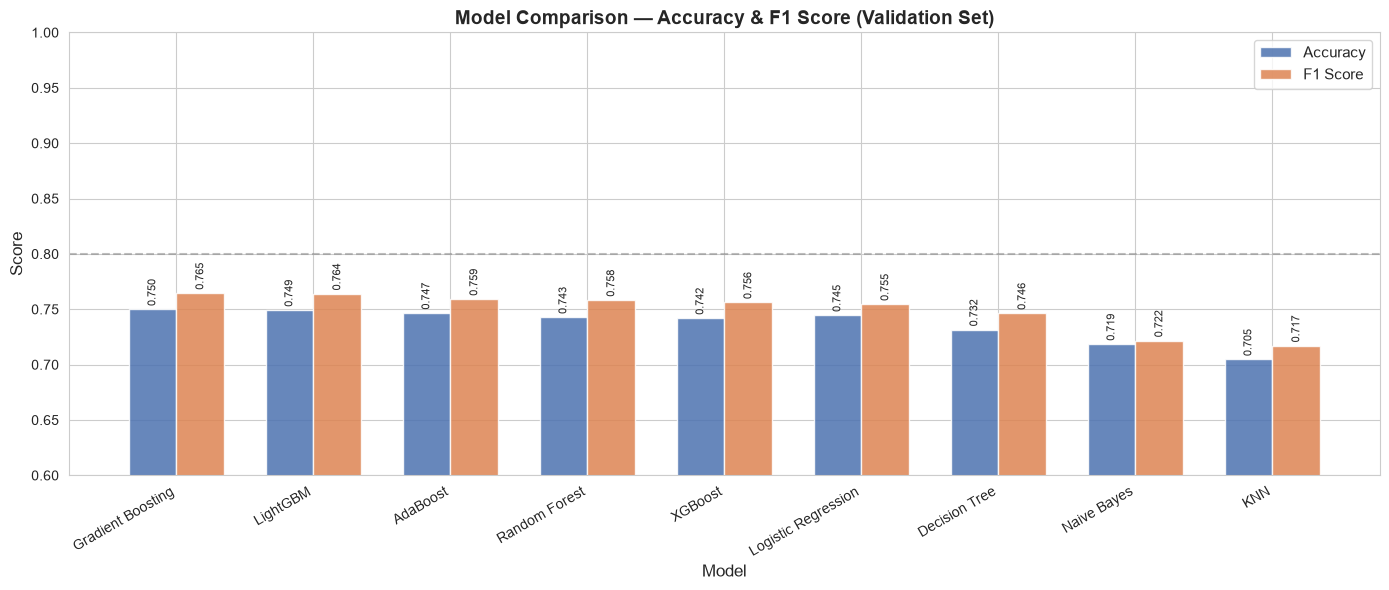

In [15]:
# === BAR CHART: ACCURACY & F1 ALL MODELS ===
plot_df = results_df.copy()
x = np.arange(len(plot_df))
width = 0.35

fig, ax = plt.subplots(figsize=(14, 6))
bars1 = ax.bar(x - width/2, plot_df['Val_Accuracy'], width, label='Accuracy', color='#4C72B0', alpha=0.85)
bars2 = ax.bar(x + width/2, plot_df['Val_F1'],       width, label='F1 Score', color='#DD8452', alpha=0.85)

ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Model Comparison — Accuracy & F1 Score (Validation Set)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(plot_df['Model'], rotation=30, ha='right', fontsize=10)
ax.set_ylim(0.6, 1.0)
ax.legend(fontsize=11)
ax.axhline(y=0.8, color='gray', linestyle='--', alpha=0.5, label='0.8 threshold')

for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8, rotation=90)

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'model_comparison_bar.png', bbox_inches='tight')
plt.show()

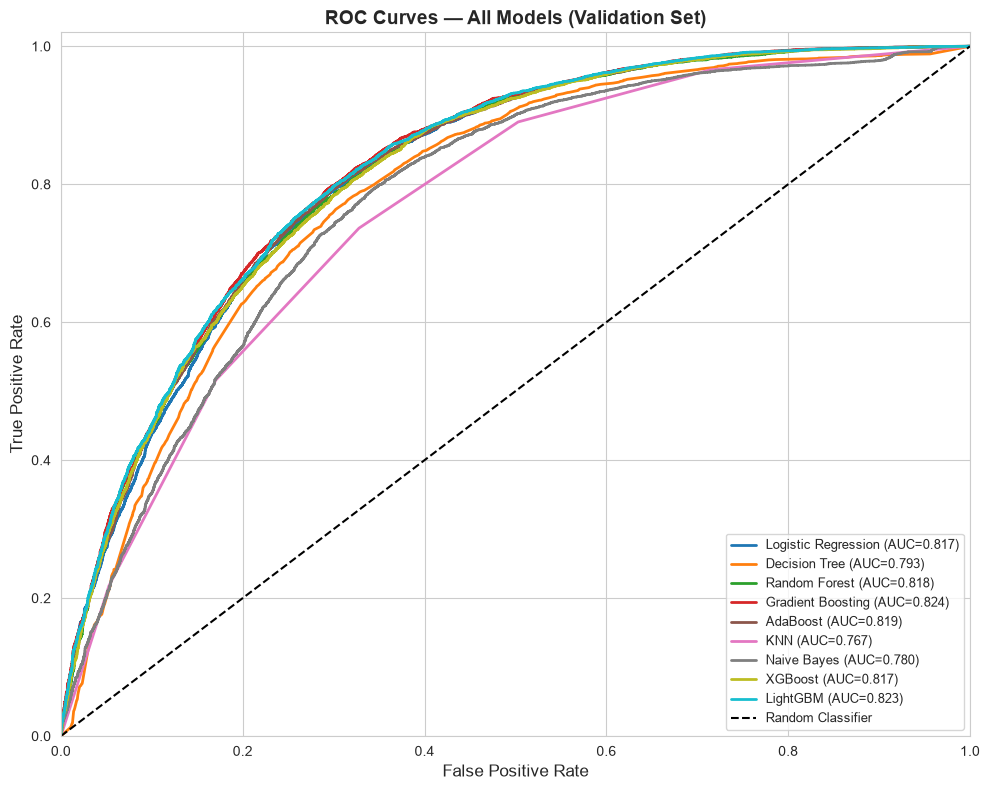

In [16]:
# === ROC CURVES — ALL MODELS OVERLAY ===
fig, ax = plt.subplots(figsize=(10, 8))
colors = plt.cm.tab10(np.linspace(0, 1, len(models)))

for (name, model), color in zip(trained_models.items(), colors):
    if '(Tuned)' in name:
        continue  # skip tuned for main ROC
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_val_sc)[:, 1]
        fpr, tpr, _ = roc_curve(y_val, y_prob)
        auc = roc_auc_score(y_val, y_prob)
        ax.plot(fpr, tpr, lw=2, color=color, label=f'{name} (AUC={auc:.3f})')

ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves — All Models (Validation Set)', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'roc_curves_all_models.png', bbox_inches='tight')
plt.show()

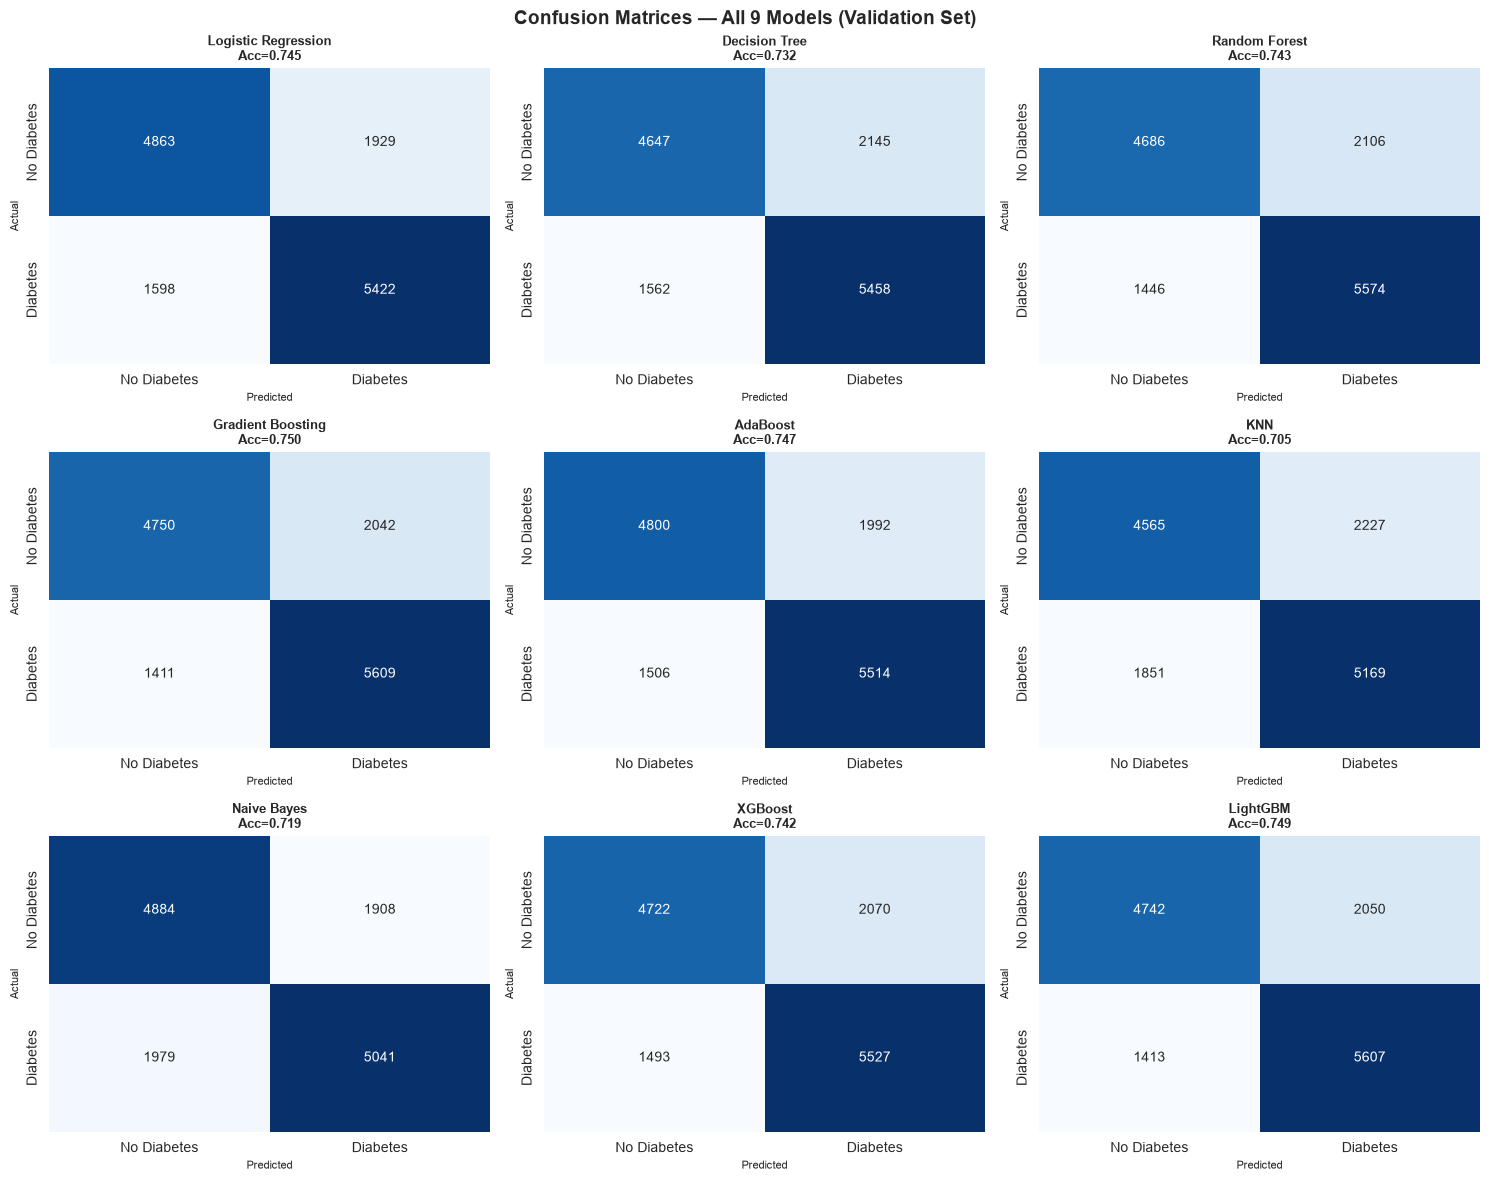

In [17]:
# === CONFUSION MATRICES — 3x3 GRID (9 MODELS) ===
model_list = [(n, m) for n, m in trained_models.items() if '(Tuned)' not in n]
n_models = min(9, len(model_list))

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, (name, model) in enumerate(model_list[:9]):
    y_pred = model.predict(X_val_sc)
    cm = confusion_matrix(y_val, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['No Diabetes', 'Diabetes'],
                yticklabels=['No Diabetes', 'Diabetes'],
                cbar=False)
    acc = accuracy_score(y_val, y_pred)
    axes[i].set_title(f'{name}\nAcc={acc:.3f}', fontsize=9, fontweight='bold')
    axes[i].set_xlabel('Predicted', fontsize=8)
    axes[i].set_ylabel('Actual', fontsize=8)

for j in range(i + 1, 9):
    axes[j].set_visible(False)

plt.suptitle('Confusion Matrices — All 9 Models (Validation Set)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'confusion_matrices_all.png', bbox_inches='tight')
plt.show()

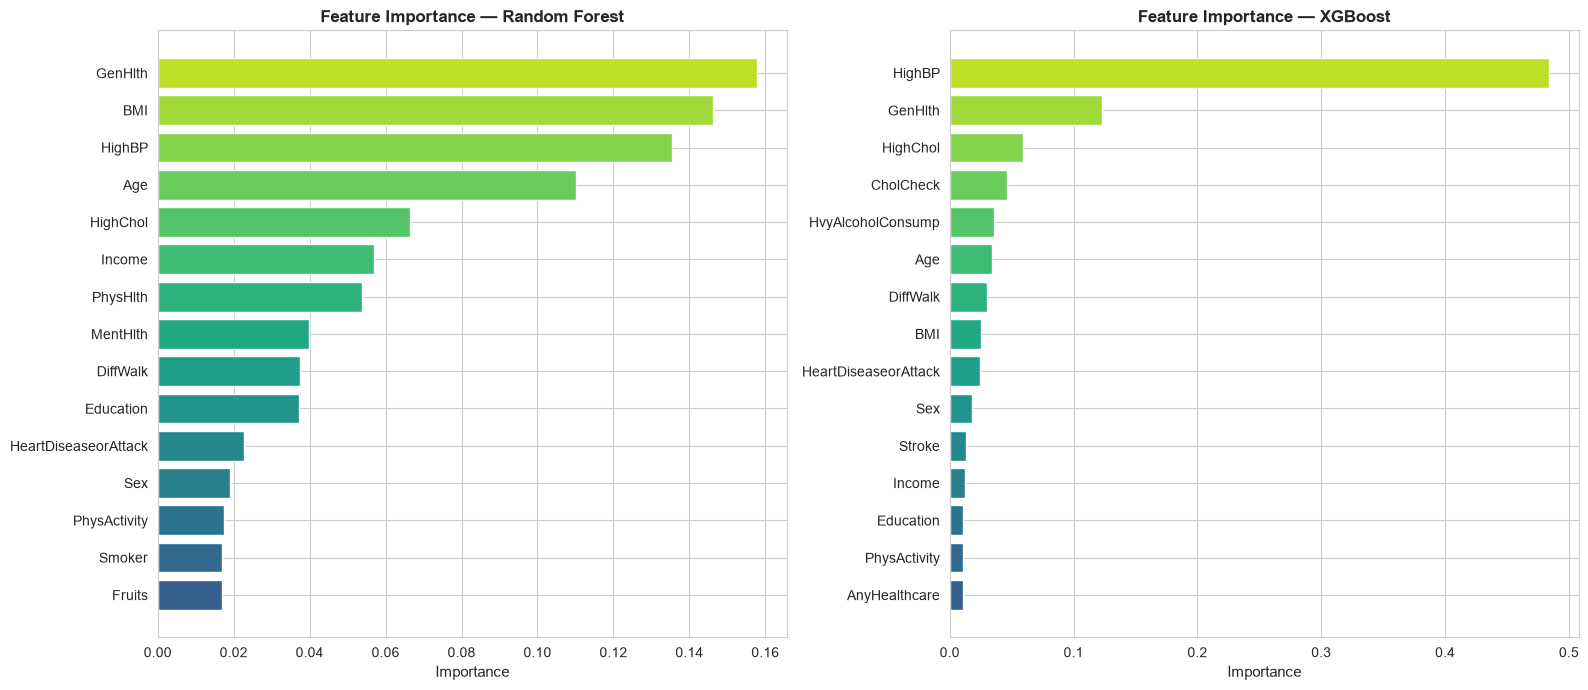

In [18]:
# === FEATURE IMPORTANCE — RF & XGB ===
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
importance_models = ['Random Forest', 'XGBoost']

for ax, name in zip(axes, importance_models):
    if name not in trained_models:
        ax.text(0.5, 0.5, f'{name} not available', ha='center')
        continue
    model = trained_models[name]
    importances = model.feature_importances_
    feat_imp = pd.DataFrame({'Feature': FEATURE_COLS, 'Importance': importances})
    feat_imp = feat_imp.sort_values('Importance', ascending=True).tail(15)
    
    ax.barh(feat_imp['Feature'], feat_imp['Importance'],
            color=plt.cm.viridis(np.linspace(0.3, 0.9, len(feat_imp))))
    ax.set_title(f'Feature Importance — {name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Importance', fontsize=11)

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'feature_importance_rf_xgb.png', bbox_inches='tight')
plt.show()

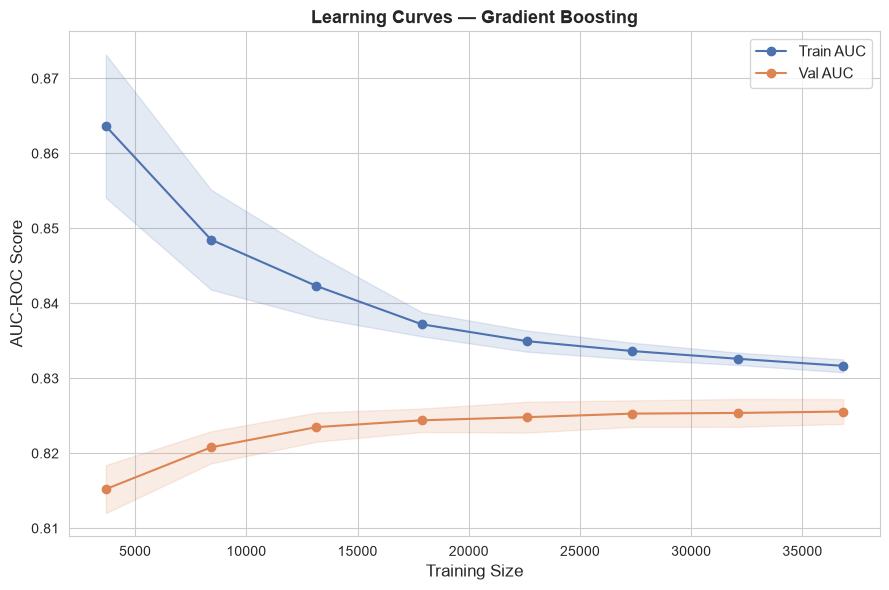

In [19]:
# === LEARNING CURVES — BEST MODEL ===
train_sizes = np.linspace(0.1, 1.0, 8)
train_sz, train_scores, val_scores = learning_curve(
    best_model, X_train_sc, y_train,
    train_sizes=train_sizes, cv=3,
    scoring='roc_auc', n_jobs=-1
)

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(train_sz, train_scores.mean(axis=1), 'o-', color='#4C72B0', label='Train AUC')
ax.fill_between(train_sz,
                train_scores.mean(axis=1) - train_scores.std(axis=1),
                train_scores.mean(axis=1) + train_scores.std(axis=1), alpha=0.15, color='#4C72B0')
ax.plot(train_sz, val_scores.mean(axis=1), 'o-', color='#DD8452', label='Val AUC')
ax.fill_between(train_sz,
                val_scores.mean(axis=1) - val_scores.std(axis=1),
                val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.15, color='#DD8452')
ax.set_xlabel('Training Size', fontsize=12)
ax.set_ylabel('AUC-ROC Score', fontsize=12)
ax.set_title(f'Learning Curves — {best_model_name}', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'learning_curves_best_model.png', bbox_inches='tight')
plt.show()

---
## 🔬 SECTION 4 — Cross-test on Binary Dataset

In [20]:
# === LOAD & SCALE TEST DATASET ===
X_test_raw = df_test[FEATURE_COLS].values
y_test = df_test[TARGET_COL].values

X_test_sc = X_test_raw.copy()
X_test_sc[:, numeric_idx] = scaler.transform(X_test_raw[:, numeric_idx])

print(f'Test set shape : {X_test_sc.shape}')
print(f'Class balance  : {np.bincount(y_test.astype(int))}')
print(f'Class ratio    : {np.bincount(y_test.astype(int)) / len(y_test)}')
print('✅ Test set ready!')

Test set shape : (253680, 21)
Class balance  : [218334  35346]
Class ratio    : [0.86066698 0.13933302]
✅ Test set ready!


In [21]:
# === PREDICT ON TEST SET — ALL 9 MODELS ===
test_results = []

for name, model in trained_models.items():
    if '(Tuned)' in name:
        continue
    y_pred = model.predict(X_test_sc)
    y_prob = model.predict_proba(X_test_sc)[:, 1] if hasattr(model, 'predict_proba') else None
    
    test_results.append({
        'Model':         name,
        'Test_Accuracy': accuracy_score(y_test, y_pred),
        'Test_F1':       f1_score(y_test, y_pred),
        'Test_Precision':precision_score(y_test, y_pred),
        'Test_Recall':   recall_score(y_test, y_pred),
        'Test_AUC':      roc_auc_score(y_test, y_prob) if y_prob is not None else np.nan,
    })

test_results_df = pd.DataFrame(test_results).sort_values('Test_AUC', ascending=False).reset_index(drop=True)
print('=== Test Set Results (Binary Dataset) ===')
display(test_results_df.style
    .background_gradient(subset=['Test_AUC', 'Test_F1', 'Test_Accuracy'], cmap='YlOrRd')
    .format({c: '{:.4f}' for c in test_results_df.columns if c != 'Model'})
    .set_caption('Performance on Imbalanced Binary Dataset')
)

=== Test Set Results (Binary Dataset) ===


,Model,Test_Accuracy,Test_F1,Test_Precision,Test_Recall,Test_AUC
0,Random Forest,0.7384,0.4810,0.3324,0.8700,0.8776
1,XGBoost,0.7250,0.4539,0.3138,0.8204,0.8440
2,LightGBM,0.7215,0.4469,0.3090,0.8074,0.8365
3,Gradient Boosting,0.7211,0.4437,0.3072,0.7981,0.8311
4,AdaBoost,0.7259,0.4423,0.3087,0.7800,0.8251
5,Decision Tree,0.7144,0.4392,0.3023,0.8026,0.8229
6,Logistic Regression,0.7293,0.4422,0.3102,0.7700,0.8227
7,KNN,0.7081,0.4361,0.2984,0.8102,0.8189
8,Naive Bayes,0.7234,0.4182,0.2958,0.7135,0.7850


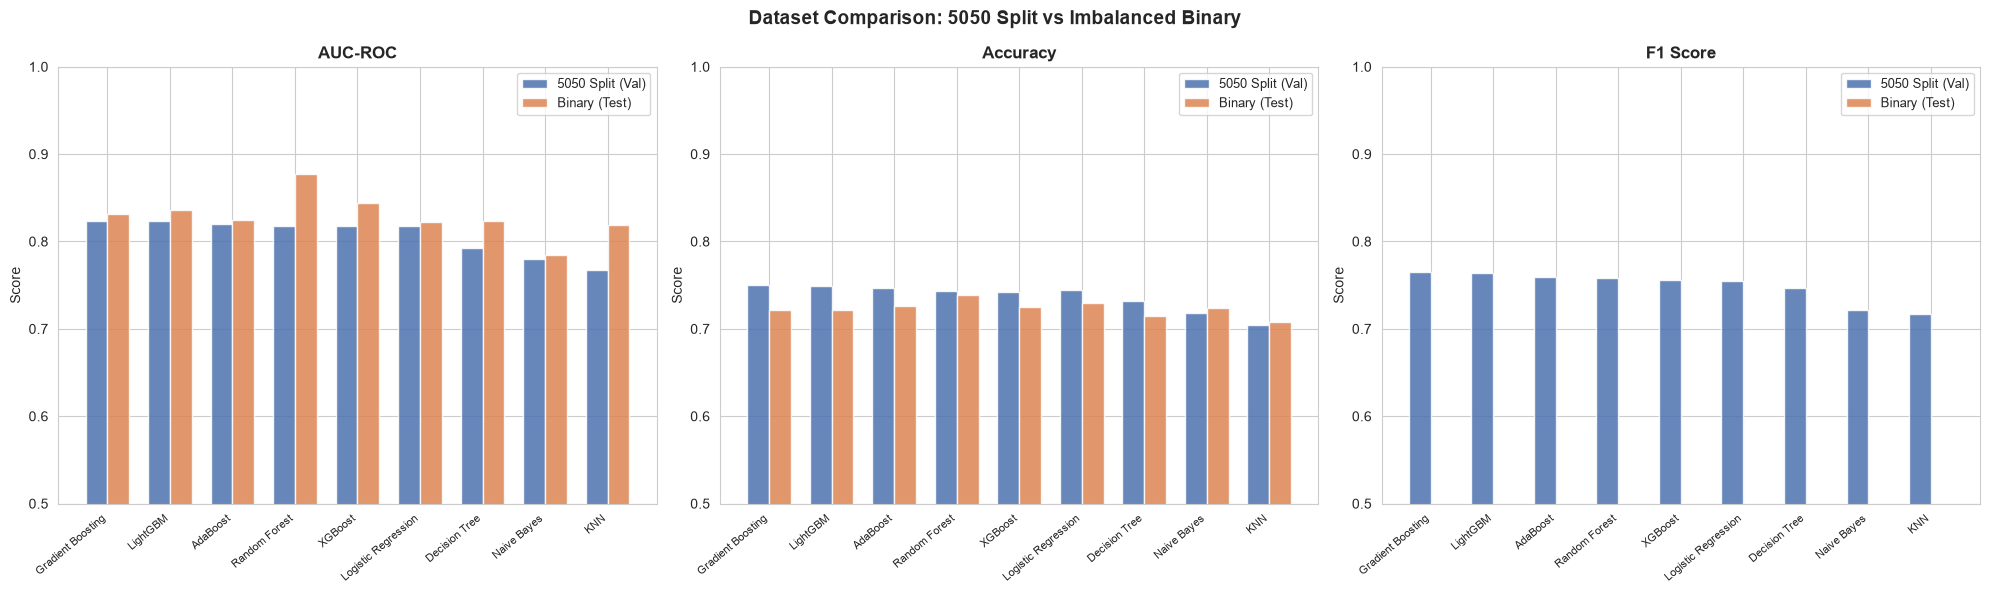

In [22]:
# === GROUPED BAR: 5050 vs BINARY DATASET ===
merged = pd.merge(
    results_df[['Model', 'Val_Accuracy', 'Val_F1', 'Val_AUC']],
    test_results_df[['Model', 'Test_Accuracy', 'Test_F1', 'Test_AUC']],
    on='Model', how='inner'
)

metrics_to_compare = [('Val_AUC', 'Test_AUC', 'AUC-ROC'),
                      ('Val_Accuracy', 'Test_Accuracy', 'Accuracy'),
                      ('Val_F1', 'Test_F1', 'F1 Score')]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, (val_col, test_col, metric_name) in zip(axes, metrics_to_compare):
    x = np.arange(len(merged))
    w = 0.35
    ax.bar(x - w/2, merged[val_col],  w, label='5050 Split (Val)', color='#4C72B0', alpha=0.85)
    ax.bar(x + w/2, merged[test_col], w, label='Binary (Test)',     color='#DD8452', alpha=0.85)
    ax.set_title(metric_name, fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(merged['Model'], rotation=40, ha='right', fontsize=8)
    ax.set_ylim(0.5, 1.0)
    ax.legend(fontsize=9)
    ax.set_ylabel('Score')

plt.suptitle('Dataset Comparison: 5050 Split vs Imbalanced Binary', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'dataset_comparison_grouped.png', bbox_inches='tight')
plt.show()

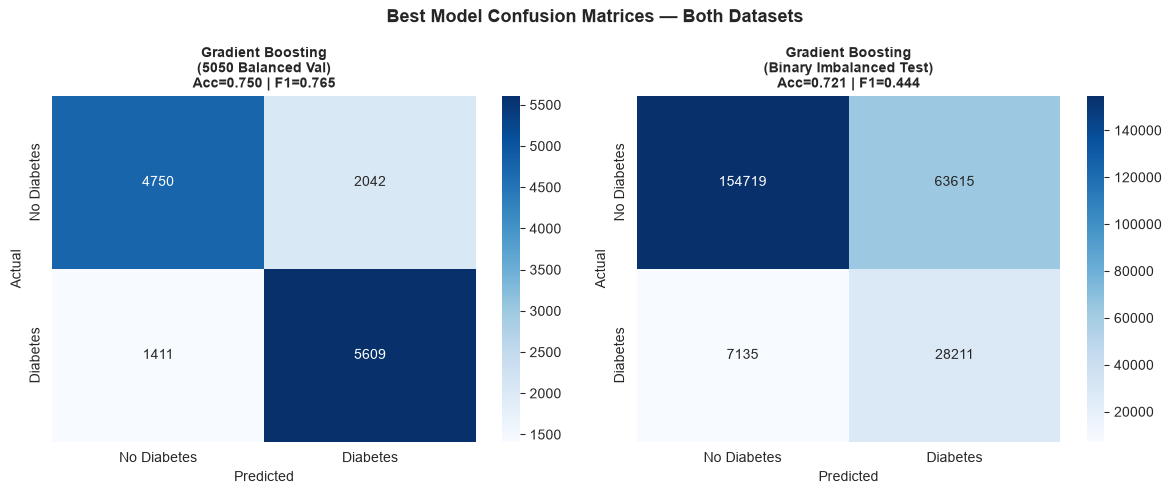

In [23]:
# === CONFUSION MATRICES BEST MODEL — SIDE BY SIDE ===
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (X_data, y_data, title) in zip(axes, [
    (X_val_sc, y_val, f'{best_model_name}\n(5050 Balanced Val)'),
    (X_test_sc, y_test, f'{best_model_name}\n(Binary Imbalanced Test)'),
]):
    y_pred = best_model.predict(X_data)
    cm = confusion_matrix(y_data, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['No Diabetes', 'Diabetes'],
                yticklabels=['No Diabetes', 'Diabetes'])
    acc = accuracy_score(y_data, y_pred)
    f1  = f1_score(y_data, y_pred)
    ax.set_title(f'{title}\nAcc={acc:.3f} | F1={f1:.3f}', fontsize=10, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.suptitle('Best Model Confusion Matrices — Both Datasets', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'confusion_matrices_best_model_both.png', bbox_inches='tight')
plt.show()

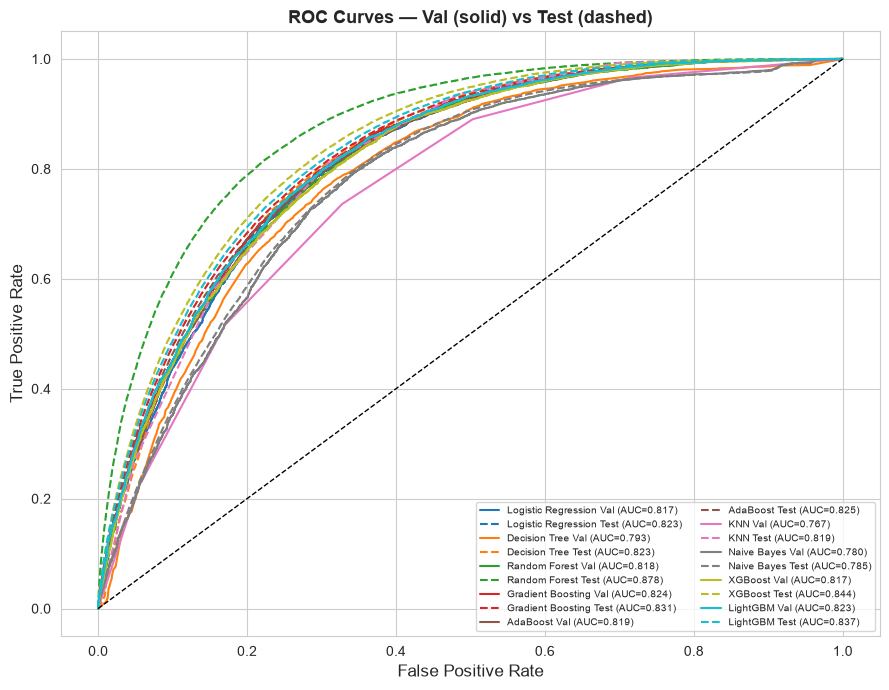

In [24]:
# === ROC CURVES — 2 DATASETS COMPARISON ===
fig, ax = plt.subplots(figsize=(9, 7))
colors = plt.cm.tab10(np.linspace(0, 1, len(models)))

for (name, model), color in zip(trained_models.items(), colors):
    if '(Tuned)' in name:
        continue
    if not hasattr(model, 'predict_proba'):
        continue
    # Val
    fpr_v, tpr_v, _ = roc_curve(y_val, model.predict_proba(X_val_sc)[:, 1])
    auc_v = roc_auc_score(y_val, model.predict_proba(X_val_sc)[:, 1])
    ax.plot(fpr_v, tpr_v, lw=1.5, color=color, linestyle='-',
            label=f'{name} Val (AUC={auc_v:.3f})')
    # Test
    fpr_t, tpr_t, _ = roc_curve(y_test, model.predict_proba(X_test_sc)[:, 1])
    auc_t = roc_auc_score(y_test, model.predict_proba(X_test_sc)[:, 1])
    ax.plot(fpr_t, tpr_t, lw=1.5, color=color, linestyle='--',
            label=f'{name} Test (AUC={auc_t:.3f})')

ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves — Val (solid) vs Test (dashed)', fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'roc_curves_dataset_comparison.png', bbox_inches='tight')
plt.show()

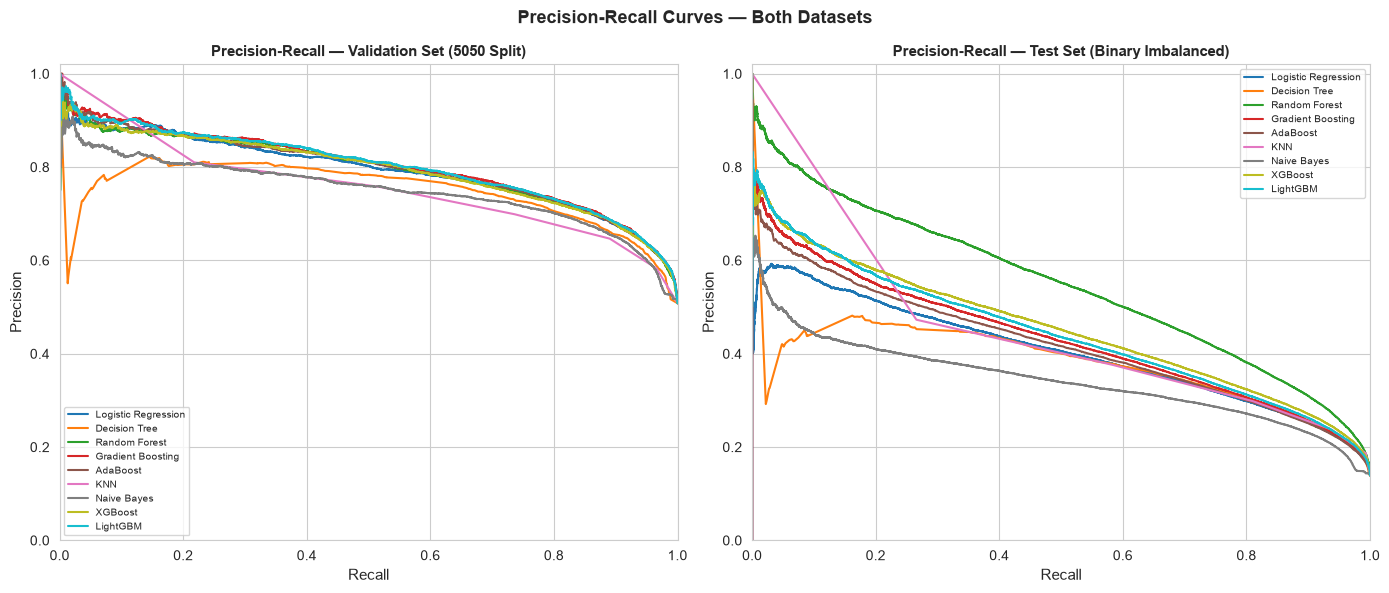

In [25]:
# === PRECISION-RECALL CURVES ===
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = plt.cm.tab10(np.linspace(0, 1, len(models)))

for ax, (X_data, y_data, title) in zip(axes, [
    (X_val_sc, y_val, 'Validation Set (5050 Split)'),
    (X_test_sc, y_test, 'Test Set (Binary Imbalanced)'),
]):
    for (name, model), color in zip(trained_models.items(), colors):
        if '(Tuned)' in name or not hasattr(model, 'predict_proba'):
            continue
        y_prob = model.predict_proba(X_data)[:, 1]
        prec, rec, _ = precision_recall_curve(y_data, y_prob)
        ax.plot(rec, prec, lw=1.5, color=color, label=name)
    ax.set_xlabel('Recall', fontsize=11)
    ax.set_ylabel('Precision', fontsize=11)
    ax.set_title(f'Precision-Recall — {title}', fontsize=11, fontweight='bold')
    ax.legend(fontsize=7)
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1.02])

plt.suptitle('Precision-Recall Curves — Both Datasets', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'precision_recall_curves.png', bbox_inches='tight')
plt.show()

---
## 📚 SECTION 5 — RAG Pipeline (PDF Knowledge Base)

In [26]:
# === CHECK DEPENDENCIES ===
import subprocess, importlib

required = {
    'sentence_transformers': 'sentence-transformers',
    'chromadb': 'chromadb',
    'fitz': 'PyMuPDF',
}

for module, pkg in required.items():
    try:
        importlib.import_module(module)
        print(f'✅ {pkg} — installed')
    except ImportError:
        print(f'⚠️  {pkg} not found. Installing...')
        subprocess.run(['pip', 'install', pkg, '-q'], check=True)
        print(f'✅ {pkg} — installed successfully')

print('\nAll RAG dependencies ready!')

✅ sentence-transformers — installed
✅ chromadb — installed
✅ PyMuPDF — installed

All RAG dependencies ready!


In [27]:
# === IMPORTS RAG ===
import fitz  # PyMuPDF
import chromadb
from sentence_transformers import SentenceTransformer
import re

# Add rag/ to sys.path
rag_dir = str(BASE_DIR / 'rag')
if rag_dir not in sys.path:
    sys.path.insert(0, rag_dir)
    print(f'Added to sys.path: {rag_dir}')

# Try importing custom RAG modules
try:
    from pdf_processor import PDFProcessor
    from rag_pipeline import RAGPipeline
    USE_CUSTOM_RAG = True
    print('✅ Custom RAG modules loaded (pdf_processor, rag_pipeline)')
except ImportError as e:
    USE_CUSTOM_RAG = False
    print(f'ℹ️  Custom RAG modules not found ({e}). Using built-in RAG implementation.')

print('✅ RAG imports complete!')

Added to sys.path: D:\N4_K1\HTTM\Code\TieuLuan\KB_RAG\rag
ℹ️  Custom RAG modules not found (cannot import name 'PDFProcessor' from 'pdf_processor' (D:\N4_K1\HTTM\Code\TieuLuan\KB_RAG\rag\pdf_processor.py)). Using built-in RAG implementation.
✅ RAG imports complete!


In [28]:
# === PROCESS PDF ===
chunks = []
pdf_loaded = False

def extract_pdf_chunks(pdf_path, chunk_size=500, overlap=100):
    """Extract text chunks from PDF using PyMuPDF."""
    doc = fitz.open(str(pdf_path))
    full_text = ''
    for page in doc:
        full_text += page.get_text() + ' '
    doc.close()
    
    # Clean text
    full_text = re.sub(r'\s+', ' ', full_text).strip()
    
    # Split into chunks
    words = full_text.split()
    chunks = []
    for i in range(0, len(words), chunk_size - overlap):
        chunk = ' '.join(words[i:i + chunk_size])
        if len(chunk.split()) >= 50:  # skip tiny chunks
            chunks.append(chunk)
    return chunks

if PDF_PATH.exists():
    print(f'Processing PDF: {PDF_PATH.name} ({PDF_PATH.stat().st_size / 1024:.1f} KB)')
    try:
        if USE_CUSTOM_RAG:
            processor = PDFProcessor(str(PDF_PATH))
            chunks = processor.extract_chunks()
        else:
            chunks = extract_pdf_chunks(PDF_PATH)
        pdf_loaded = True
        print(f'✅ Extracted {len(chunks)} chunks from PDF')
        print(f'\nFirst chunk preview:\n{chunks[0][:300]}...')
    except Exception as e:
        print(f'❌ Error processing PDF: {e}')
else:
    print(f'⚠️  PDF not found at: {PDF_PATH}')
    print('Using demo chunks for demonstration...')
    chunks = [
        'Phác đồ điều trị tiểu đường type 2: Mục tiêu điều trị là kiểm soát đường huyết, phòng ngừa biến chứng. Với bệnh nhân béo phì (BMI > 30), ưu tiên dùng Metformin kết hợp thay đổi lối sống tích cực.',
        'Metformin là thuốc đầu tay trong điều trị đái tháo đường type 2. Liều khởi đầu: 500mg x 2 lần/ngày hoặc 850mg x 1 lần/ngày, uống cùng bữa ăn. Tăng liều từ từ sau mỗi 2 tuần.',
        'Thay đổi lối sống cho tiền tiểu đường: Giảm cân 5-10% trọng lượng cơ thể, tập thể dục ít nhất 150 phút/tuần cường độ vừa, chế độ ăn ít carbohydrate, nhiều rau xanh.',
        'Mục tiêu HbA1c: Với hầu hết bệnh nhân tiểu đường type 2, mục tiêu HbA1c < 7.0%. Bệnh nhân cao tuổi hoặc nhiều bệnh đồng mắc có thể nới lỏng mục tiêu HbA1c < 8.0%.',
        'Insulin được chỉ định khi: HbA1c > 10%, đường huyết lúc đói > 300 mg/dL, hoặc bệnh nhân có triệu chứng nặng. Liều khởi đầu: 10 đơn vị Insulin nền buổi tối.',
    ]
    pdf_loaded = True
    print(f'✅ Loaded {len(chunks)} demo chunks')

Processing PDF: HD-chan-doan-dieu-tri-DTD-2017_07_19-Approved.pdf (900.9 KB)
✅ Extracted 42 chunks from PDF

First chunk preview:
1 BỘ Y TẾ ________ CỘNG HÒA XÃ HỘI CHỦ NGHĨA VIỆT NAM Độc lập - Tự do - Hạnh phúc HƯỚNG DẪN CHẨN ĐOÁN VÀ ĐIỀU TRỊ ĐÁI THÁO ĐƯỜNG TÍP 2 (Ban hành kèm theo Quyết định số 3319/QĐ-BYT ngày 19 tháng 7 năm 2017 của Bộ trưởng Bộ Y tế) I. ĐẠI CƯƠNG Bệnh đái tháo đường là bệnh rối loạn chuyển hóa không đồng ...


In [29]:
%%time
# === BUILD CHROMADB INDEX ===
EMBED_MODEL_NAME = 'paraphrase-multilingual-MiniLM-L12-v2'
COLLECTION_NAME  = 'diabetes_guidelines'

print(f'Loading embedding model: {EMBED_MODEL_NAME}...')
embed_model = SentenceTransformer(EMBED_MODEL_NAME)
print('✅ Embedding model loaded!')

# Init ChromaDB (in-memory)
chroma_client = chromadb.Client()

# Delete collection if exists
try:
    chroma_client.delete_collection(COLLECTION_NAME)
except Exception:
    pass

collection = chroma_client.create_collection(
    name=COLLECTION_NAME,
    metadata={'hnsw:space': 'cosine'}
)

# Embed & add to collection
print(f'Embedding {len(chunks)} chunks...')
embeddings = embed_model.encode(chunks, show_progress_bar=True, batch_size=32)

collection.add(
    documents=chunks,
    embeddings=embeddings.tolist(),
    ids=[f'chunk_{i}' for i in range(len(chunks))],
    metadatas=[{'source': PDF_PATH.name, 'chunk_id': i} for i in range(len(chunks))]
)

print(f'✅ ChromaDB index built: {collection.count()} documents')

Loading embedding model: paraphrase-multilingual-MiniLM-L12-v2...


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

✅ Embedding model loaded!
Embedding 42 chunks...


Batches:   0%|          | 0/2 [00:00<?, ?it/s]

✅ ChromaDB index built: 42 documents
CPU times: total: 13.7 s
Wall time: 34.7 s


In [30]:
# === RAG DEMO — 4 QUERIES ===
def rag_query(query, n_results=3):
    """Query the ChromaDB collection and return formatted results."""
    q_embed = embed_model.encode([query])[0].tolist()
    results = collection.query(
        query_embeddings=[q_embed],
        n_results=n_results,
        include=['documents', 'distances', 'metadatas']
    )
    return results

DEMO_QUERIES = [
    'Phác đồ điều trị tiểu đường type 2 ở bệnh nhân béo phì?',
    'Liều dùng Metformin khởi đầu?',
    'Thay đổi lối sống cho bệnh nhân tiền tiểu đường?',
    'Mục tiêu kiểm soát HbA1c?',
]

print('=' * 70)
print('RAG DEMO — Clinical Guidelines Query System')
print('=' * 70)

all_query_results = []

for i, query in enumerate(DEMO_QUERIES, 1):
    print(f'\n[Query {i}] {query}')
    print('-' * 60)
    results = rag_query(query, n_results=2)
    
    for j, (doc, dist, meta) in enumerate(zip(
        results['documents'][0],
        results['distances'][0],
        results['metadatas'][0]
    ), 1):
        similarity = 1 - dist  # cosine distance → similarity
        print(f'  📄 Source #{j} | Similarity: {similarity:.3f} | Chunk ID: {meta["chunk_id"]}')
        print(f'     {doc[:250]}...' if len(doc) > 250 else f'     {doc}')
    
    all_query_results.append({'query': query, 'results': results})

print('\n' + '=' * 70)
print('✅ RAG Demo complete!')

RAG DEMO — Clinical Guidelines Query System

[Query 1] Phác đồ điều trị tiểu đường type 2 ở bệnh nhân béo phì?
------------------------------------------------------------
  📄 Source #1 | Similarity: 0.701 | Chunk ID: 16
     bằng chứng trái ngược. Do đó nếu sử dụng cũng cần hạn chế đến mức tối thiểu. 3.2. Điều trị đái tháo đường bằng thuốc a) Các nhóm thuốc hạ glucose huyết đường uống và thuốc dạng tiêm không thuộc nhóm insulin theo Phụ lục 03 được ban hành kèm theo Quyế...
  📄 Source #2 | Similarity: 0.694 | Chunk ID: 2
     chẩn đoán ĐTĐ. 2. Chẩn đoán tiền đái tháo đường Chẩn đoán tiền đái tháo đường khi có một trong các rối loạn sau đây: -­ Rối loạn glucose huyết đói (impaired fasting glucose: IFG): Glucose huyết tương lúc đói từ 100 (5,6mmol/L) đến 125 mg/dL (6,9 mmol...

[Query 2] Liều dùng Metformin khởi đầu?
------------------------------------------------------------
  📄 Source #1 | Similarity: 0.628 | Chunk ID: 28
     nhân có nguy cơ nhiễm acid lactic như suy thận, nghiện rư

In [31]:
# === DISPLAY RESULTS — FORMATTED TABLE ===
from IPython.display import HTML

html_parts = ['<h3>RAG Query Results</h3>']

for qr in all_query_results:
    q = qr['query']
    html_parts.append(f'<h4 style="color:#2c7be5;">❓ {q}</h4><ul>')
    for doc, dist, meta in zip(
        qr['results']['documents'][0],
        qr['results']['distances'][0],
        qr['results']['metadatas'][0]
    ):
        sim = 1 - dist
        snippet = doc[:300] + '...' if len(doc) > 300 else doc
        html_parts.append(
            f'<li><b>Source:</b> {meta["source"]} | '
            f'<b>Chunk {meta["chunk_id"]}</b> | '
            f'<b>Similarity:</b> {sim:.3f}<br>'
            f'<em>{snippet}</em></li>'
        )
    html_parts.append('</ul><hr>')

display(HTML(''.join(html_parts)))

---
## 💾 SECTION 6 — Save Models & Metadata

In [32]:
# === SAVE BEST MODEL & SCALER ===
best_model_path  = MODELS_DIR / 'best_model.pkl'
scaler_path      = MODELS_DIR / 'scaler.pkl'

try:
    joblib.dump(best_model, best_model_path, compress=3)
    print(f'✅ Best model saved → {best_model_path}')
    print(f'   Model type: {type(best_model).__name__}')
    print(f'   File size : {best_model_path.stat().st_size / 1024:.1f} KB')
except Exception as e:
    print(f'❌ Error saving model: {e}')

try:
    joblib.dump(scaler, scaler_path, compress=3)
    print(f'✅ Scaler saved → {scaler_path}')
    print(f'   File size : {scaler_path.stat().st_size / 1024:.1f} KB')
except Exception as e:
    print(f'❌ Error saving scaler: {e}')

# Save all trained models
for model_name, model_obj in trained_models.items():
    safe_name = model_name.replace(' ', '_').replace('(', '').replace(')', '').lower()
    path = MODELS_DIR / f'{safe_name}.pkl'
    try:
        joblib.dump(model_obj, path, compress=3)
        print(f'  💾 Saved: {path.name} ({path.stat().st_size / 1024:.1f} KB)')
    except Exception as e:
        print(f'  ❌ Failed {model_name}: {e}')

✅ Best model saved → D:\N4_K1\HTTM\Code\TieuLuan\KB_RAG\models\best_model.pkl
   Model type: GradientBoostingClassifier
   File size : 44.1 KB
✅ Scaler saved → D:\N4_K1\HTTM\Code\TieuLuan\KB_RAG\models\scaler.pkl
   File size : 0.5 KB
  💾 Saved: logistic_regression.pkl (0.7 KB)
  💾 Saved: decision_tree.pkl (36.8 KB)
  💾 Saved: random_forest.pkl (13839.6 KB)
  💾 Saved: gradient_boosting.pkl (44.1 KB)
  💾 Saved: adaboost.pkl (13.3 KB)
  💾 Saved: knn.pkl (834.2 KB)
  💾 Saved: naive_bayes.pkl (1.2 KB)
  💾 Saved: xgboost.pkl (144.0 KB)
  💾 Saved: lightgbm.pkl (141.6 KB)
  💾 Saved: random_forest_tuned.pkl (6217.1 KB)
  💾 Saved: xgboost_tuned.pkl (45.5 KB)
  💾 Saved: lightgbm_tuned.pkl (264.1 KB)


In [33]:
# === SAVE MODEL METADATA JSON ===
import datetime

best_row = results_df.iloc[0]
test_best_row = test_results_df[test_results_df['Model'] == best_model_name].iloc[0] \
    if best_model_name in test_results_df['Model'].values else None

metadata = {
    'project': 'Diabetes Diagnosis with ML & RAG',
    'created_at': datetime.datetime.now().isoformat(),
    'random_seed': RANDOM_SEED,
    'datasets': {
        'train': {
            'path': str(TRAIN_CSV),
            'rows': int(df_train_clean.shape[0]),
            'features': int(df_train_clean.shape[1] - 1),
        },
        'test': {
            'path': str(TEST_CSV),
            'rows': int(df_test.shape[0]),
            'features': int(df_test.shape[1] - 1),
        }
    },
    'preprocessing': {
        'scaled_features': NUMERIC_FEATURES,
        'scaler': 'StandardScaler',
        'val_split': 0.2,
        'stratified': True,
    },
    'best_model': {
        'name': best_model_name,
        'type': type(best_model).__name__,
        'params': str(best_model.get_params()),
        'val_accuracy':  float(round(best_row['Val_Accuracy'], 4)),
        'val_f1':        float(round(best_row['Val_F1'], 4)),
        'val_auc':       float(round(best_row['Val_AUC'], 4)),
        'test_accuracy': float(round(test_best_row['Test_Accuracy'], 4)) if test_best_row is not None else None,
        'test_f1':       float(round(test_best_row['Test_F1'], 4))       if test_best_row is not None else None,
        'test_auc':      float(round(test_best_row['Test_AUC'], 4))      if test_best_row is not None else None,
    },
    'all_models_val': results_df[['Model', 'Val_Accuracy', 'Val_F1', 'Val_AUC']].round(4).to_dict(orient='records'),
    'features': FEATURE_COLS,
    'target': TARGET_COL,
    'rag': {
        'pdf_source': PDF_PATH.name,
        'n_chunks': len(chunks),
        'embedding_model': EMBED_MODEL_NAME,
        'vector_db': 'ChromaDB',
    }
}

metadata_path = MODELS_DIR / 'model_metadata.json'
try:
    with open(metadata_path, 'w', encoding='utf-8') as f:
        json.dump(metadata, f, ensure_ascii=False, indent=2)
    print(f'✅ Metadata saved → {metadata_path}')
    print(f'   File size: {metadata_path.stat().st_size / 1024:.1f} KB')
except Exception as e:
    print(f'❌ Error saving metadata: {e}')

print('\n--- Metadata Preview ---')
print(json.dumps({k: v for k, v in metadata.items() if k != 'all_models_val'}, indent=2, ensure_ascii=False))

✅ Metadata saved → D:\N4_K1\HTTM\Code\TieuLuan\KB_RAG\models\model_metadata.json
   File size: 3.1 KB

--- Metadata Preview ---
{
  "project": "Diabetes Diagnosis with ML & RAG",
  "created_at": "2026-10-14T23:53:32.319447",
  "random_seed": 42,
  "datasets": {
    "train": {
      "path": "D:\\N4_K1\\HTTM\\Code\\TieuLuan\\KB_RAG\\data\\diabetes_binary_5050split_health_indicators_BRFSS2015.csv",
      "rows": 69057,
      "features": 21
    },
    "test": {
      "path": "D:\\N4_K1\\HTTM\\Code\\TieuLuan\\KB_RAG\\data\\diabetes_binary_health_indicators_BRFSS2015.csv",
      "rows": 253680,
      "features": 21
    }
  },
  "preprocessing": {
    "scaled_features": [
      "BMI",
      "MentHlth",
      "PhysHlth",
      "Age"
    ],
    "scaler": "StandardScaler",
    "val_split": 0.2,
    "stratified": true
  },
  "best_model": {
    "name": "Gradient Boosting",
    "type": "GradientBoostingClassifier",
    "params": "{'ccp_alpha': 0.0, 'criterion': 'deprecated', 'init': None, 'learnin

In [34]:
# === VERIFY SAVED FILES ===
print('=== Verifying Saved Files ===')
print(f'\nModels directory: {MODELS_DIR}\n')

if MODELS_DIR.exists():
    saved_files = list(MODELS_DIR.glob('*'))
    if saved_files:
        total_size = 0
        for f in sorted(saved_files):
            size_kb = f.stat().st_size / 1024
            total_size += size_kb
            print(f'  ✅ {f.name:<40} {size_kb:>8.1f} KB')
        print(f'\n  Total: {len(saved_files)} files, {total_size/1024:.2f} MB')
    else:
        print('  ⚠️  No files found in models directory')
else:
    print(f'  ❌ Models directory not found: {MODELS_DIR}')

print(f'\nReports directory: {REPORTS_DIR}\n')
if REPORTS_DIR.exists():
    figs = list(REPORTS_DIR.glob('*.png'))
    for f in sorted(figs):
        print(f'  🖼️  {f.name}')
    print(f'\n  Total: {len(figs)} figures saved')

=== Verifying Saved Files ===

Models directory: D:\N4_K1\HTTM\Code\TieuLuan\KB_RAG\models

  ✅ adaboost.pkl                                 13.3 KB
  ✅ best_model.pkl                               44.1 KB
  ✅ decision_tree.pkl                            36.8 KB
  ✅ gradient_boosting.pkl                        44.1 KB
  ✅ knn.pkl                                     834.2 KB
  ✅ lightgbm.pkl                                141.6 KB
  ✅ lightgbm_tuned.pkl                          264.1 KB
  ✅ logistic_regression.pkl                       0.7 KB
  ✅ model_metadata.json                           3.1 KB
  ✅ naive_bayes.pkl                               1.2 KB
  ✅ random_forest.pkl                         13839.6 KB
  ✅ random_forest_tuned.pkl                    6217.1 KB
  ✅ scaler.pkl                                    0.5 KB
  ✅ xgboost.pkl                                 144.0 KB
  ✅ xgboost_tuned.pkl                            45.5 KB

  Total: 15 files, 21.12 MB

Reports directory: D:\N

In [35]:
# === FINAL SUMMARY ===
from IPython.display import HTML

best_val  = results_df.iloc[0]
best_test = test_results_df.iloc[0]

summary_html = f"""
<div style="font-family: Arial; max-width: 800px; margin: auto;">
<h2 style="color:#1a73e8; border-bottom: 2px solid #1a73e8;">🩺 Diabetes Diagnosis Pipeline — Summary</h2>

<h3>📊 Dataset</h3>
<ul>
  <li><b>Train (5050 balanced):</b> {df_train_clean.shape[0]:,} samples, {len(FEATURE_COLS)} features</li>
  <li><b>Test  (imbalanced):</b>   {df_test.shape[0]:,} samples</li>
  <li><b>Target:</b> {TARGET_COL}</li>
</ul>

<h3>🤖 Models Trained: {len(models)}</h3>
<table border="1" style="border-collapse:collapse; width:100%;">
  <tr style="background:#1a73e8; color:white;">
    <th style="padding:8px;">Model</th>
    <th style="padding:8px;">Val Accuracy</th>
    <th style="padding:8px;">Val F1</th>
    <th style="padding:8px;">Val AUC</th>
  </tr>
"""

for _, row in results_df.iterrows():
    bg = '#e8f4fd' if row['Model'] == best_model_name else 'white'
    bold = 'bold' if row['Model'] == best_model_name else 'normal'
    summary_html += f"""
  <tr style="background:{bg}; font-weight:{bold};">
    <td style="padding:6px;">{row['Model']}</td>
    <td style="padding:6px; text-align:center;">{row['Val_Accuracy']:.4f}</td>
    <td style="padding:6px; text-align:center;">{row['Val_F1']:.4f}</td>
    <td style="padding:6px; text-align:center;">{row['Val_AUC']:.4f}</td>
  </tr>"""

summary_html += f"""
</table>

<h3>🏆 Best Model: {best_model_name}</h3>
<ul>
  <li><b>Validation AUC:</b> {best_val['Val_AUC']:.4f}</li>
  <li><b>Validation Accuracy:</b> {best_val['Val_Accuracy']:.4f}</li>
  <li><b>Validation F1:</b> {best_val['Val_F1']:.4f}</li>
  <li><b>Test AUC:</b> {best_test['Test_AUC']:.4f}</li>
</ul>

<h3>📚 RAG Pipeline</h3>
<ul>
  <li><b>PDF:</b> {PDF_PATH.name}</li>
  <li><b>Chunks:</b> {len(chunks)}</li>
  <li><b>Embedding Model:</b> {EMBED_MODEL_NAME}</li>
  <li><b>Vector DB:</b> ChromaDB (in-memory)</li>
</ul>

<h3>💾 Artifacts Saved</h3>
<ul>
  <li>best_model.pkl</li>
  <li>scaler.pkl</li>
  <li>model_metadata.json</li>
  <li>{len(list(REPORTS_DIR.glob('*.png')))} figures in reports/figures/</li>
</ul>

<p style="color:green; font-weight:bold;">✅ Pipeline completed successfully!</p>
</div>
"""

display(HTML(summary_html))

Model,Val Accuracy,Val F1,Val AUC
Gradient Boosting,0.7500,0.7646,0.8237
LightGBM,0.7493,0.7641,0.8234
AdaBoost,0.7467,0.7592,0.8194
Random Forest,0.7428,0.7584,0.8181
XGBoost,0.7420,0.7562,0.8174
Logistic Regression,0.7446,0.7546,0.8174
Decision Tree,0.7316,0.7465,0.7927
Naive Bayes,0.7186,0.7217,0.7800
KNN,0.7047,0.7171,0.7669
